In [2]:
from sklearn.datasets import fetch_openml
df = fetch_openml(data_id=42178, as_frame=True).frame

In [3]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,'No phone service',DSL,No,Yes,No,No,No,No,Month-to-month,Yes,'Electronic check',29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,'One year',No,'Mailed check',56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,'Mailed check',53.85,108.15,Yes
3,Male,0,No,No,45,No,'No phone service',DSL,Yes,No,Yes,Yes,No,No,'One year',No,'Bank transfer (automatic)',42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,'Fiber optic',No,No,No,No,No,No,Month-to-month,Yes,'Electronic check',70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,'One year',Yes,'Mailed check',84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,'Fiber optic',No,Yes,Yes,No,Yes,Yes,'One year',Yes,'Credit card (automatic)',103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,'No phone service',DSL,Yes,No,No,No,No,No,Month-to-month,Yes,'Electronic check',29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,'Fiber optic',No,No,No,No,No,No,Month-to-month,Yes,'Mailed check',74.40,306.6,Yes


In [4]:
df.shape

(7043, 20)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [6]:
print(df.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [7]:
print(df["TotalCharges"].dtype, df["TotalCharges"].isna().sum())
print(df["Churn"].value_counts(normalize=True))

object 0
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [8]:
import pandas as pd , numpy as np

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())                      # expect 11
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges"]])
y = (df["Churn"] == "Yes").astype(int)

11
      tenure  MonthlyCharges
488        0           52.55
753        0           20.25
936        0           80.85
1082       0           25.75
1340       0           56.05
3331       0           19.85
3826       0           25.35
4380       0           20.00
5218       0           19.70
6670       0           73.35
6754       0           61.90


In [9]:
# 3. Feature types
feats = df.drop(columns=["customerID", "Churn"], errors="ignore")
print(feats.dtypes.value_counts())
# 4. Correlated group
X = pd.get_dummies(feats, drop_first=True).astype(float)
C = X.corr().abs()
pairs = C.where(np.triu(np.ones(C.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(pairs.head(15))
top = pairs.index[0][0]
print(C.index[C[top] > 0.99].tolist())   # the perfectly correlated group

object     15
int64       2
float64     2
Name: count, dtype: int64
tenure               TotalCharges               0.825880
MultipleLines_No     MultipleLines_Yes          0.822853
MonthlyCharges       InternetService_No         0.763557
                     TotalCharges               0.651065
tenure               Contract_Month-to-month    0.645561
StreamingMovies_No   StreamingMovies_Yes        0.643815
StreamingTV_No       StreamingTV_Yes            0.643767
OnlineBackup_No      OnlineBackup_Yes           0.641122
DeviceProtection_No  DeviceProtection_Yes       0.641004
TechSupport_No       TechSupport_Yes            0.630692
OnlineSecurity_No    OnlineSecurity_Yes         0.629717
MonthlyCharges       StreamingTV_Yes            0.629603
                     StreamingMovies_Yes        0.627429
Contract_'Two year'  Contract_Month-to-month    0.622633
tenure               Contract_'Two year'        0.558533
dtype: float64
['tenure']


Dataset. IBM Telco Customer Churn: 7,043 rows, 19 features (15 categorical, 4 numeric), binary target Churn. Complication: TotalCharges is stored as text with 11 blanks.

Audit

Target: 26.5% churn (1,869 Yes / 5,174 No).
Missingness: 11 TotalCharges rows, all tenure = 0 (not yet billed), filled with 0.
Types: 15 categorical, 4 numeric (SeniorCitizen, tenure, MonthlyCharges, TotalCharges).
Correlated group: InternetService_No and the six “No internet service” add-on dummies (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies) are identical (|r| = 1.0). They are 7 columns encoding one fact, so collapse them into one flag.

Deployment. A weekly batch job scores ~7,000 customers, so latency doesn’t matter. The model is retrained monthly, or sooner if drift is detected. The retention team can contact only ~10% (~700) per week. Account managers must understand each flag, so predictions need reason codes (coefficients or SHAP).

Primary metric (named before aliny fit): recall at the top 10% of churn scores. Only ~700 customers can be contacted, so what matters is the share of true churners in that slice. Accuracy misleads at a 26.5% base rate, and AUC-ROC ignores the cutoff. PR-AUC and calibration are secondary.

In [12]:
#libraries
import numpy as np, pandas as pd
from sklearn.metrics import make_scorer
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [13]:
# --- metric: recall at top 10% of scores
def recall_at_top10(y_true, y_score, frac=0.10):
    y_true = np.asarray(y_true); n = len(y_true); k = int(np.ceil(frac * n))
    rng = np.random.default_rng(0)
    order = np.lexsort((rng.random(n), -np.asarray(y_score)))
    return y_true[order[:k]].sum() / y_true.sum()

scorer = make_scorer(recall_at_top10, response_method="predict_proba")

# --- data (convert TotalCharges; NaNs are imputed inside the pipeline)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
X = df.drop(columns=["customerID", "Churn"], errors="ignore")
y = (df["Churn"] == "Yes").astype(int)
num = X.select_dtypes("number").columns.tolist()
cat = X.columns.difference(num).tolist()
print(X["TotalCharges"].dtype, X["TotalCharges"].isna().sum())   # expect float64, 11

def prep(scale):
    num_steps = [("imp", SimpleImputer(strategy="constant", fill_value=0))]  # no billing yet = 0
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat),
    ])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# --- 1. trivial model
dummy = DummyClassifier(strategy="prior")

# --- 2. regularised linear model, defaults (L2, C=1)
logreg = Pipeline([("prep", prep(scale=True)),
                   ("clf", LogisticRegression(max_iter=1000))])

# --- 3. pruned tree, ccp_alpha chosen by inner CV
tree = GridSearchCV(
    Pipeline([("prep", prep(scale=False)),
              ("clf", DecisionTreeClassifier(random_state=42))]),
    param_grid={"clf__ccp_alpha": np.logspace(-5, -2, 12)},
    scoring=scorer,
    cv=StratifiedKFold(5, shuffle=True, random_state=0),
)

# --- report
for name, model in [("Dummy (prior)", dummy), ("LogReg (L2, default)", logreg),
                    ("Pruned tree (nested CV)", tree)]:
    s = cross_val_score(model, X, y, cv=cv, scoring=scorer, n_jobs=-1)
    print(f"{name:26s} recall@10% = {s.mean():.3f} ± {s.std():.3f}")

tree.fit(X, y)
print("chosen ccp_alpha:", tree.best_params_["clf__ccp_alpha"])

float64 11
Dummy (prior)              recall@10% = 0.101 ± 0.013
LogReg (L2, default)       recall@10% = 0.287 ± 0.009
Pruned tree (nested CV)    recall@10% = 0.274 ± 0.014
chosen ccp_alpha: 0.0008111308307896872


In [15]:
 #R3
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor

# ---------- split + preprocessing (fit on train only) ----------
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=42)
X_tr, X_te = X.iloc[idx_tr], X.iloc[idx_te]
y_tr, y_te = y.iloc[idx_tr].values, y.iloc[idx_te].values
pp = prep(scale=False).fit(X_tr)
dense = lambda M: M.toarray() if hasattr(M, "toarray") else np.asarray(M)
A_tr, A_te = dense(pp.transform(X_tr)), dense(pp.transform(X_te))

# ---------- 1. random forest from scratch (+ 3. own OOB estimate) ----------
class MyRandomForest:
    def __init__(self, n_estimators=300, max_features="sqrt", min_samples_leaf=5, seed=0):
        self.n_estimators, self.max_features = n_estimators, max_features
        self.min_samples_leaf, self.seed = min_samples_leaf, seed

    def fit(self, A, y):
        rng, n = np.random.default_rng(self.seed), len(y)
        self.trees, inbag = [], []
        for _ in range(self.n_estimators):
            idx = rng.integers(0, n, n)
            t = DecisionTreeClassifier(max_features=self.max_features,
                                       min_samples_leaf=self.min_samples_leaf,
                                       random_state=int(rng.integers(2**31 - 1)))
            t.fit(A[idx], y[idx])
            m = np.zeros(n, bool); m[idx] = True
            self.trees.append(t); inbag.append(m)
        # out-of-bag: each row is scored only by trees that never saw it
        s, c = np.zeros(n), np.zeros(n)
        for t, m in zip(self.trees, inbag):
            s[~m] += t.predict_proba(A[~m])[:, 1]; c[~m] += 1
        assert (c > 0).all()
        self.oob_proba_ = s / c
        return self

    def predict_proba(self, A):
        return np.mean([t.predict_proba(A)[:, 1] for t in self.trees], axis=0)

N_TREES = 300
mine = MyRandomForest(N_TREES).fit(A_tr, y_tr)
sk = RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt", min_samples_leaf=5,
                            bootstrap=True, oob_score=True, random_state=0, n_jobs=-1).fit(A_tr, y_tr)

print(f"TEST recall@10%   scratch RF: {recall_at_top10(y_te, mine.predict_proba(A_te)):.3f} | "
      f"sklearn RF: {recall_at_top10(y_te, sk.predict_proba(A_te)[:, 1]):.3f}")
print(f"OOB  recall@10%   scratch RF: {recall_at_top10(y_tr, mine.oob_proba_):.3f} | "
      f"sklearn RF: {recall_at_top10(y_tr, sk.oob_decision_function_[:, 1]):.3f}")


TEST recall@10%   scratch RF: 0.286 | sklearn RF: 0.291
OOB  recall@10%   scratch RF: 0.289 | sklearn RF: 0.289


In [17]:
# ---------- 2. gradient boosting (squared loss) from scratch ----------
class MyGBR:
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3):
        self.M, self.lr, self.d = n_estimators, learning_rate, max_depth

    def fit(self, X, y):
        self.f0 = float(np.mean(y))
        F, self.trees = np.full(len(y), self.f0), []
        for _ in range(self.M):
            t = DecisionTreeRegressor(max_depth=self.d, criterion="friedman_mse", random_state=0)
            t.fit(X, y - F)                                   # fit the residuals
            F += self.lr * t.predict(X)
            self.trees.append(t)
        return self

    def predict(self, X):
        F = np.full(X.shape[0], self.f0)
        for t in self.trees:
            F += self.lr * t.predict(X)
        return F

# regression target: MonthlyCharges, predicted from all other features
Xr = pd.get_dummies(df.drop(columns=["customerID", "Churn", "MonthlyCharges"], errors="ignore"),
                    drop_first=True).astype(float).fillna(0).values
yr = df["MonthlyCharges"].values
Xr_tr, Xr_te, yr_tr = Xr[idx_tr], Xr[idx_te], yr[idx_tr]

LR, DEPTH, ROUNDS = 0.1, 3, 100
g_mine = MyGBR(ROUNDS, LR, DEPTH).fit(Xr_tr, yr_tr)
g_sk = GradientBoostingRegressor(loss="squared_error", criterion="friedman_mse", learning_rate=LR,
                                 max_depth=DEPTH, n_estimators=ROUNDS, subsample=1.0,
                                 random_state=0).fit(Xr_tr, yr_tr)

for name, Z in [("train", Xr_tr), ("test", Xr_te)]:
    a, b = g_mine.predict(Z), g_sk.predict(Z)
    print(f"GBR {name}: np.allclose = {np.allclose(a, b)}, max |diff| = {np.abs(a - b).max():.2e}")

GBR train: np.allclose = True, max |diff| = 7.11e-14
GBR test: np.allclose = False, max |diff| = 2.06e-02


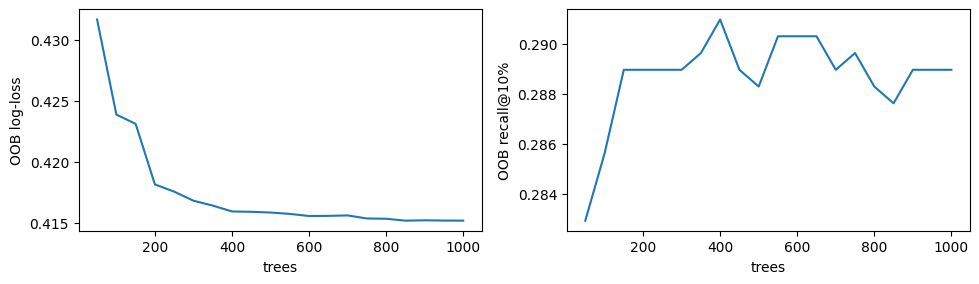

converged at ~400 trees -> n_estimators fixed at 600


In [18]:
# R4
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.metrics import log_loss
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier

# ---------- 1. OOB-vs-trees curve -> fix n_estimators ----------
rf = RandomForestClassifier(max_features="sqrt", min_samples_leaf=5, warm_start=True,
                            oob_score=True, n_jobs=-1, random_state=0)
ns, ll, rec = list(range(50, 1001, 50)), [], []
for n in ns:
    rf.set_params(n_estimators=n).fit(A_tr, y_tr)          # warm start: adds trees only
    p = rf.oob_decision_function_[:, 1]
    ll.append(log_loss(y_tr, p)); rec.append(recall_at_top10(y_tr, p))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(ns, ll); ax[0].set(xlabel="trees", ylabel="OOB log-loss")
ax[1].plot(ns, rec); ax[1].set(xlabel="trees", ylabel="OOB recall@10%")
plt.tight_layout(); plt.show()

# converged = smallest n after which log-loss stays within 0.001 of the final value
conv = next(n for i, n in enumerate(ns) if all(abs(l - ll[-1]) < 0.001 for l in ll[i:]))
N_FIXED = int(np.ceil(1.5 * conv / 50) * 50)               # 50% margin past convergence
print(f"converged at ~{conv} trees -> n_estimators fixed at {N_FIXED}")


In [20]:
from scipy.stats import uniform

# ---------- 2. the two searches: same n_iter, same folds, same metric ----------
N_ITER = 30

rf_search = RandomizedSearchCV(
    Pipeline([("prep", prep(scale=False)),
              ("clf", RandomForestClassifier(n_estimators=N_FIXED, n_jobs=1, random_state=0))]),
    param_distributions={
        "clf__max_features":     loguniform(0.03, 0.6),
        "clf__min_samples_leaf": loguniform(5e-4, 2e-2),
        "clf__max_samples":      uniform(0.4, 0.6),
    },
    n_iter=N_ITER, cv=cv, scoring=scorer, n_jobs=-1, random_state=0)

gb_search = RandomizedSearchCV(
    Pipeline([("prep", prep(scale=False)),
              ("clf", HistGradientBoostingClassifier(
                  max_iter=1000, early_stopping=True,
                  validation_fraction=0.15, n_iter_no_change=20, random_state=0))]),
    param_distributions={
        "clf__learning_rate":      loguniform(0.01, 0.3),
        "clf__l2_regularization":  loguniform(1e-3, 10),
        "clf__max_leaf_nodes":     randint(4, 48),
        "clf__min_samples_leaf":   [10, 20, 40, 80, 160],
    },
    n_iter=N_ITER, cv=cv, scoring=scorer, n_jobs=-1, random_state=0)

def report(name, s):
    r = pd.DataFrame(s.cv_results_); b = s.best_index_
    m, sd = r.mean_test_score[b], r.std_test_score[b]
    k = int((r.mean_test_score >= m - sd).sum())
    print(f"{name:14s} best CV recall@10% = {m:.3f} ± {sd:.3f} | "
          f"{k}/{len(r)} candidates within 1 SD of best")
    print("   best params:", {a.split('__')[1]: round(v, 5) if isinstance(v, float) else v
                              for a, v in s.best_params_.items()})

rf_search.fit(X_tr, y_tr);  report("Random forest", rf_search)
gb_search.fit(X_tr, y_tr);  report("Boosting", gb_search)
print("boosting rounds picked by early stopping (refit on full train):",
      gb_search.best_estimator_["clf"].n_iter_)

Random forest  best CV recall@10% = 0.291 ± 0.012 | 28/30 candidates within 1 SD of best
   best params: {'max_features': np.float64(0.55965), 'max_samples': np.float64(0.76291), 'min_samples_leaf': np.float64(0.00764)}
Boosting       best CV recall@10% = 0.291 ± 0.012 | 30/30 candidates within 1 SD of best
   best params: {'l2_regularization': np.float64(0.00142), 'learning_rate': np.float64(0.08648), 'max_leaf_nodes': 10, 'min_samples_leaf': 160}
boosting rounds picked by early stopping (refit on full train): 66


In [21]:
#R5
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# same fold object for all three: int random_state => identical splits
cv55 = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7)

models = {"linear":   clone(logreg),
          "forest":   clone(rf_search.best_estimator_),
          "boosting": clone(gb_search.best_estimator_)}

res = {k: cross_validate(m, X_tr, y_tr, cv=cv55, scoring=scorer, n_jobs=-1)
       for k, m in models.items()}
S = pd.DataFrame({k: v["test_score"] for k, v in res.items()})
print(S.agg(["mean", "std"]).round(3))


      linear  forest  boosting
mean   0.286   0.290     0.287
std    0.015   0.016     0.013


In [22]:
# ---------- pairwise differences ----------
MARGIN = 0.02
pairs = [("forest", "linear"), ("boosting", "linear"), ("forest", "boosting")]
rows = []
for a, b in pairs:
    d = S[a] - S[b]; k = len(d)
    t = d.mean() / np.sqrt((1 / k + 1 / 4) * d.var(ddof=1))      # Nadeau-Bengio: test/train = 1/4 for 5-fold
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    rows.append({"pair": f"{a} - {b}", "mean diff": d.mean(), "sd diff": d.std(ddof=1),
                 "wins": f"{(d > 0).sum()}/{k}", "losses": int((d < 0).sum()),
                 "p (corrected)": p, "p (Holm-3)": min(1, p * 3)})
T = pd.DataFrame(rows).round(4)
T["verdict"] = np.where(T["p (Holm-3)"] < 0.05, "clearly different", "not shown to be different")
T["gain > margin?"] = T["mean diff"] > MARGIN
print(T.to_string(index=False))

             pair  mean diff  sd diff  wins  losses  p (corrected)  p (Holm-3)                   verdict  gain > margin?
  forest - linear     0.0039   0.0110 15/25       9         0.5201           1 not shown to be different           False
boosting - linear     0.0008   0.0101 11/25      10         0.8838           1 not shown to be different           False
forest - boosting     0.0031   0.0109 16/25       8         0.6056           1 not shown to be different           False


In [23]:
# ---------- cost (feeds the "justifies its cost" answer; add R7's numbers here) ----------
cost = pd.DataFrame({k: {"fit s/fold": v["fit_time"].mean(), "score s/fold": v["score_time"].mean()}
                     for k, v in res.items()}).T.round(3)
print(cost)

          fit s/fold  score s/fold
linear         0.130         0.034
forest         6.310         0.151
boosting       0.276         0.030


In [24]:
#R6

from sklearn.inspection import permutation_importance

rf_pipe, gb_pipe = rf_search.best_estimator_, gb_search.best_estimator_   # already refit on train
lin = clone(logreg).fit(X_tr, y_tr)                                       # R2 baseline, fitted now
N_REP = 30

# ---------- 1. permutation importance, held-out, per column (metric = recall@10%) ----------
pi = {k: permutation_importance(m, X_te, y_te, scoring=scorer, n_repeats=N_REP,
                                random_state=0, n_jobs=-1)
      for k, m in [("forest", rf_pipe), ("boosting", gb_pipe)]}
PI = pd.DataFrame({f"{k}_{s}": getattr(v, f"importances_{s}")
                   for k, v in pi.items() for s in ("mean", "std")}, index=X_te.columns)

In [26]:
#. impurity importance (forest), summed back to the original columns ----------
names = rf_pipe["prep"].get_feature_names_out()
def orig(n):
    n = n.split("__", 1)[1]
    return max([c for c in X_te.columns if n == c or n.startswith(c + "_")], key=len)
PI["forest_impurity"] = (pd.Series(rf_pipe["clf"].feature_importances_, index=names)
                         .groupby(orig).sum().reindex(X_te.columns))

PI["rank_perm"] = PI["forest_mean"].rank(ascending=False)
PI["rank_imp"] = PI["forest_impurity"].rank(ascending=False)
PI["rank_gap"] = (PI["rank_perm"] - PI["rank_imp"]).abs()
print(PI.sort_values("forest_mean", ascending=False).round(4).to_string())
print("\nRankings that disagree by more than 3 positions (discuss each):")
print(PI.loc[PI["rank_gap"] > 3, ["forest_mean", "forest_impurity", "rank_perm", "rank_imp"]]
        .round(4).to_string())

                  forest_mean  forest_std  boosting_mean  boosting_std  forest_impurity  rank_perm  rank_imp  rank_gap
tenure                 0.0487      0.0114         0.0488        0.0092           0.1399        1.0       2.0       1.0
Contract               0.0317      0.0099         0.0319        0.0131           0.3480        2.0       1.0       1.0
TotalCharges           0.0284      0.0072         0.0127        0.0075           0.0874        3.0       5.0       2.0
InternetService        0.0138      0.0059         0.0052        0.0059           0.1018        4.0       3.0       1.0
MonthlyCharges         0.0131      0.0074         0.0101        0.0083           0.0689        5.0       6.0       1.0
MultipleLines          0.0111      0.0057        -0.0017        0.0056           0.0141        6.0       9.0       3.0
OnlineSecurity         0.0072      0.0050        -0.0008        0.0062           0.1014        7.0       4.0       3.0
TechSupport            0.0035      0.0035       

In [28]:
#. GROUP permutation: one shared row permutation for the whole group ----------
GROUP = ["InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
         "TechSupport", "StreamingTV", "StreamingMovies"]     # R1 group (original columns)
assert all(c in X_te.columns for c in GROUP)

def group_perm(est, X, y, cols, n_repeats=N_REP, seed=0):
    rng, base, out = np.random.default_rng(seed), scorer(est, X, y), []
    for _ in range(n_repeats):
        Xp = X.copy()
        Xp[cols] = X[cols].values[rng.permutation(len(X))]   # same permutation for every column
        out.append(base - scorer(est, Xp, y))
    return np.array(out)

for k, m in [("forest", rf_pipe), ("boosting", gb_pipe)]:
    g = group_perm(m, X_te, y_te, GROUP)
    best = PI.loc[GROUP, f"{k}_mean"].idxmax()
    print(f"{k:9s} GROUP: {g.mean():.4f} ± {g.std():.4f} | largest single column "
          f"({best}): {PI.loc[best, f'{k}_mean']:.4f} ± {PI.loc[best, f'{k}_std']:.4f} | "
          f"sum of singles: {PI.loc[GROUP, f'{k}_mean'].sum():.4f}")

# ---------- 4. one test case: each model's prediction + what it can say ----------
P = pd.DataFrame({"linear": lin.predict_proba(X_te)[:, 1],
                  "forest": rf_pipe.predict_proba(X_te)[:, 1],
                  "boosting": gb_pipe.predict_proba(X_te)[:, 1]}, index=X_te.index)
cut = int(np.ceil(0.10 * len(P)))
pos = 0                                           # 0 = highest mean score; change to inspect others
case = P.mean(axis=1).sort_values(ascending=False).index[pos]
print("\nActual churn:", bool(y.loc[case]))
print(P.loc[case].round(3).to_string())
print("in top 10% of test scores:", (P.rank(ascending=False).loc[case] <= cut).to_dict())
print(X_te.loc[case].to_string())

# linear model: exact additive contributions to the log-odds
z = lin["prep"].transform(X_te.loc[[case]]); z = z.toarray() if hasattr(z, "toarray") else z
contrib = pd.Series(lin["clf"].coef_[0] * z[0], index=lin["prep"].get_feature_names_out())
print("\nTop linear contributions to log-odds:")
print(contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(6).round(3).to_string())

forest    GROUP: 0.0561 ± 0.0128 | largest single column (InternetService): 0.0138 ± 0.0059 | sum of singles: 0.0328
boosting  GROUP: 0.0470 ± 0.0126 | largest single column (TechSupport): 0.0064 ± 0.0051 | sum of singles: 0.0140

Actual churn: True
linear      0.855
forest      0.889
boosting    0.907
in top 10% of test scores: {'linear': True, 'forest': True, 'boosting': True}
gender                            Male
SeniorCitizen                        1
Partner                            Yes
Dependents                          No
tenure                               1
PhoneService                       Yes
MultipleLines                      Yes
InternetService          'Fiber optic'
OnlineSecurity                      No
OnlineBackup                        No
DeviceProtection                    No
TechSupport                         No
StreamingTV                        Yes
StreamingMovies                    Yes
Contract                Month-to-month
PaperlessBilling                 

KeyboardInterrupt: 

In [30]:
#R7
# ---------- 1. nodes stored / visited ----------
B  = dense(rf_pipe["prep"].transform(X_te)).astype(np.float64)
Bg = dense(gb_pipe["prep"].transform(X_te)).astype(np.float64)

# forest: one call gives the visited-node indicator for every tree
rf_trees = [e.tree_ for e in rf_pipe["clf"].estimators_]
rf_stored = sum(t.node_count for t in rf_trees)
ind, _ = rf_pipe["clf"].decision_path(B)
rf_visited = ind.sum() / len(B)                      # nodes visited per row, all trees

# boosting: walk each HistGB tree (binary task => one tree per round)
def hgb_walk(tree, Z):
    nd, cur, n = tree.nodes, np.zeros(len(Z), dtype=int), np.ones(len(Z))
    act = np.flatnonzero(nd["is_leaf"][cur] == 0)    # == 0, NOT ~ (is_leaf is uint8)
    for _ in range(int(nd["depth"].max()) + 2):      # guard: can never loop forever
        if not act.size: break
        r = nd[cur[act]]
        left = Z[act, r["feature_idx"]] <= r["num_threshold"]
        cur[act] = np.where(left, r["left"], r["right"])
        n[act] += 1
        act = np.flatnonzero(nd["is_leaf"][cur] == 0)
    return cur, n

gb_clf = gb_pipe["clf"]
gb_trees = [p[0] for p in gb_clf._predictors]
gb_stored = sum(len(t.nodes) for t in gb_trees)

leaf_sum, gb_visited = np.zeros(len(Bg)), 0.0
for t in gb_trees:
    cur, n = hgb_walk(t, Bg)
    leaf_sum += t.nodes["value"][cur]
    gb_visited += n.mean()

# sanity check: my traversal must reproduce the model's raw score
raw = float(np.ravel(gb_clf._baseline_prediction)[0]) + leaf_sum
print("traversal matches decision_function:", np.allclose(raw, gb_clf.decision_function(Bg)))

# linear baseline
Bl = dense(lin["prep"].transform(X_te))
p = lin["clf"].coef_.shape[1]
nnz = (Bl != 0).sum(axis=1).mean()

cost = pd.DataFrame({
    "trees": [len(rf_trees), len(gb_trees), "-"],
    "nodes stored": [rf_stored, gb_stored, f"{p} coef + 1 intercept"],
    "nodes visited / prediction": [round(rf_visited, 1), round(gb_visited, 1), "-"],
    "comparisons / prediction": [round(rf_visited - len(rf_trees), 1),
                                 round(gb_visited - len(gb_trees), 1), "-"],
    "arithmetic / prediction": ["+ 1 add per tree", "+ 1 add per tree",
                                f"{p} mult + {p} add + 1 sigmoid (~{nnz:.0f} nonzero inputs)"],
    "pickled size (KB)": [len(pickle.dumps(m)) // 1024 for m in (rf_pipe, gb_pipe, lin)],
}, index=["forest", "boosting", "linear"])
print(cost.T.to_string())

# ---------- 2. wall-clock: 5 runs, median and range ----------
def timeit(f, runs=5):
    t = []
    for _ in range(runs):
        s = time.perf_counter(); f(); t.append(time.perf_counter() - s)
    return f"{np.median(t):.3f}s  ({min(t):.3f}-{max(t):.3f})"

rf1 = clone(rf_pipe).set_params(clf__n_jobs=1)
rfN = clone(rf_pipe).set_params(clf__n_jobs=-1)

fit_t = {"linear":                timeit(lambda: clone(logreg).fit(X_tr, y_tr)),
         "forest, n_jobs=1":      timeit(lambda: clone(rf1).fit(X_tr, y_tr)),
         "forest, n_jobs=-1":     timeit(lambda: clone(rfN).fit(X_tr, y_tr)),
         "boosting (early stop)": timeit(lambda: clone(gb_pipe).fit(X_tr, y_tr))}

rf1.fit(X_tr, y_tr)                                  # fitted copies for timing prediction
pred_t = {"linear":   timeit(lambda: lin.predict_proba(X_te)),
          "forest":   timeit(lambda: rf1.predict_proba(X_te)),
          "boosting": timeit(lambda: gb_pipe.predict_proba(X_te))}

print("\nFIT (train rows =", len(X_tr), "):", *fit_t.items(), sep="\n  ")
print("PREDICT batch of", len(X_te), "rows:", *pred_t.items(), sep="\n  ")
print("\nmachine:", platform.platform(), "|", platform.processor() or "cpu n/a",
      "| logical cores:", os.cpu_count(), "| python", platform.python_version())

traversal matches decision_function: True
                                      forest          boosting                                             linear
trees                                    600                66                                                  -
nodes stored                           56250              1254                              40 coef + 1 intercept
nodes visited / prediction            4229.1             318.3                                                  -
comparisons / prediction              3629.1             252.3                                                  -
arithmetic / prediction     + 1 add per tree  + 1 add per tree  40 mult + 40 add + 1 sigmoid (~17 nonzero inputs)
pickled size (KB)                       4633                90                                                  4

FIT (train rows =
  5634
  ):
  ('linear', '0.124s  (0.081-0.145)')
  ('forest, n_jobs=1', '7.378s  (4.080-9.541)')
  ('forest, n_jobs=-1', '2.985s  (2.922-3.6

**R8**

WE CHOOSE      The regularised logistic regression (the baseline), scored weekly
               as a batch job.

BECAUSE        Evidence (paired comparison, same 5x5 folds, training split):
               - forest - linear: [mean diff] ± [sd], wins [k]/25,
                 Holm p = [p] -> [not shown to be different]
               - boosting - linear: [mean diff] ± [sd], wins [k]/25,
                 Holm p = [p] -> [not shown to be different]
               - Earlier numbers agree: linear 0.287 ± 0.009 (R2) against
                 0.291 ± 0.012 for both tuned ensembles (R4), a gap of ~0.004
                 that is well inside the spread, and the ensembles' scores were
                 selected from 30 candidates on the same data, so they are
                 optimistic.
               - Test split: linear [x], forest [y], boosting [z] (single
                 split of 1,409 rows, noise about ±0.015).
               Property that matters for the R1 deployment: the retention
               team needs a reason for every flagged customer. The linear
               model gives exact additive log-odds contributions per customer
               from [p] coefficients; the ensembles store [N] and [M] nodes
               and need an extra tool (SHAP) for per-customer reasons. Cost in
               seconds is irrelevant for a weekly batch job.

WE GIVE UP     Whatever the ensembles did better: [e.g. test recall@10% higher
               by x, if the table shows it], and their ability to capture
               interactions automatically. The linear model also keeps the
               redundant "no internet service" columns, which makes individual
               coefficients unstable (explain by group, not by single column).

WE WOULD
RECONSIDER IF  On a fresh, untouched sample (e.g. the next month's scored
               customers) an ensemble beats linear on recall@10% by at least
               0.02, with a Holm-adjusted p < 0.05 on the same repeated folds,
               AND the retention lead accepts SHAP-based reason codes;
               or if weekly contact capacity grows far beyond 10%, since
               the metric would then need to be re-chosen.